# EDA: kỹ năng tuyển dụng và mức lương CNTT

**Notebook đã chuẩn bị cell, chưa thực thi.** Chọn kernel **Python (IT Career Insight)**
và chạy từ trên xuống. Biểu đồ và CSV chỉ được tạo khi bạn bấm chạy.

Phân tích chi tiết dùng **train của bộ VN CNTT rộng v1.0.1**. Không mở nhãn validation/test
để tìm giả thuyết, chọn kỹ năng hoặc điều chỉnh mô hình. Các số đếm toàn nguồn chỉ mô tả
quy trình làm sạch. Đây là mẫu tin có lương công khai, không phải thống kê toàn thị trường.

Mục tiêu: top kỹ năng xuất hiện, kỹ năng có median lương cao, quan hệ kinh nghiệm–lương,
so sánh vai trò/khu vực, độ phủ ngày đăng và giới hạn dữ liệu. Lương ở đây là **trung điểm
lương chào tuyển VND/tháng, chưa rõ gross/net**, không phải lương thực nhận.

## 1. Môi trường và đường dẫn

In [1]:
from pathlib import Path
import hashlib
import json
import os
import sys
from datetime import datetime, timezone
from uuid import uuid4

# Chạy được khi Jupyter mở từ thư mục ML hoặc ML/notebooks.
cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents]
             if (p / "configs/salary.yaml").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Hãy mở notebook từ thư mục dự án ML.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

SEED = 42
SPLIT_VERSION = "v1.0.1"
sns.set_theme(style="whitegrid", font="DejaVu Sans")
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

print("Python:", sys.version.split()[0])
print("Dự án:", ROOT)


Python: 3.11.17
Dự án: /Users/scara2906/Downloads/ML


## 2. Kiểm tra snapshot, đọc **chỉ train** của bộ CNTT rộng

In [2]:
COHORT = "vn_it"
DATA = ROOT / "data/splits" / SPLIT_VERSION / COHORT
manifest = json.loads((DATA / "manifest.json").read_text())
frozen = json.loads((DATA.parent / "FROZEN.json").read_text())
assert sha256_file(ROOT / frozen["manifest_path"]) == frozen["manifest_sha256"]
snapshot = json.loads((ROOT / frozen["manifest_path"]).read_text())
expected = next(c for c in snapshot["cohorts"] if c["cohort"] == COHORT)
assert manifest == expected, "Manifest cohort đã khác snapshot đóng băng."
entry = manifest["files"]["train"]
assert sha256_file(ROOT / entry["path"]) == entry["sha256"]
train_eda = pd.read_csv(ROOT / entry["path"])
assert len(train_eda) == entry["rows"]
assert train_eda["country"].eq("Vietnam").all()
assert train_eda["salary_monthly_vnd"].gt(0).all()

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid4().hex[:6]
OUT = ROOT / "outputs/eda" / RUN_ID
OUT.mkdir(parents=True, exist_ok=False)

def save_chart(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / f"{name}.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("Dòng train:", len(train_eda))
print("Nhóm tin:", train_eda["leakage_group_id"].nunique())
print("Kết quả EDA sẽ lưu tại:", OUT)
display(train_eda[["role", "location", "experience_years", "skills", "salary_monthly_vnd"]].head())


Dòng train: 261
Nhóm tin: 257
Kết quả EDA sẽ lưu tại: /Users/scara2906/Downloads/ML/outputs/eda/20261017T092843Z_e3747c


,role,location,experience_years,skills,salary_monthly_vnd
0,ML Engineer,Hà Nội,2.0,AI;Git;LangChain;Python;Teamwork,25000000.0
1,Software Developer,Hà Nội,0.0,Hạ tầng CNTT & Quản trị hệ thống;JavaScript;Python;Triển Khai Thiết Bị Mạng;VPN,17500000.0
2,Software Developer,Hà Nội,3.0,Lập Trình C++;MES;Phân Tích Lỗi;Tự Động Hóa;Visual Studio,22000000.0
3,IT Support,Hà Nội,0.0,Analytical Skills;Communication;Customer Service;Microsoft Office 365;Problem-solving,20000000.0
4,Security Engineer,TP.HCM,10.0,Bảo Mật Thông Tin;Kỹ Năng Giao Tiếp;Quản Lý Dự Án;Quản Lý Hạ Tầng;Triển Khai Microsoft...,45000000.0


## 3. Tổng quan chất lượng nguồn

Bảng này đếm raw/clean/review và nhãn số qua các bước; không cộng các loại tiền tệ hay
cohort cha/con thành số tin IT duy nhất. Tập review vẫn được giữ nguyên để xác minh sau.

In [3]:
cleaning = json.loads((ROOT / "outputs/data_quality/cleaning/all_sources.json").read_text())
quality = pd.DataFrame([{
    "source": s["source"], "raw": s["raw_rows"], "clean": s["clean_rows"],
    "review": s["review_rows"], "labels_before_review": s["label_rows"],
} for s in cleaning["sources"]])
display(quality)
quality.to_csv(OUT / "source_quality.csv", index=False)

missing = train_eda[["role", "level", "location", "experience_years", "skills"]].isna().sum()
display(missing.rename("missing_rows").to_frame())
display(train_eda["source_dataset"].value_counts().rename("train_rows").to_frame())


,source,raw,clean,review,labels_before_review
0,user_vietnam_it_jobs,6779,885,5218,153
1,vietjobs_2025,48092,578,823,317
2,stackoverflow_2025,49191,35103,10528,18660
3,dataforge_2026_08,394300,44251,303725,14409


,missing_rows
role,0
level,143
location,0
experience_years,1
skills,0


,train_rows
source_dataset,
vietjobs_2025,207
user_vietnam_it_jobs,54


## 4. Đơn vị phân tích và phân bố lương

Các nhóm tin gần trùng được giữ cùng tập. Để một nhóm không bị đếm nhiều lần trong
biểu đồ, chọn đại diện theo `record_id` đã sắp xếp, không chọn theo mức lương.

,triệu VND/tháng
count,257.000000
mean,24.580610
std,12.085693
min,2.200000
25%,17.500000
50%,22.500000
75%,29.166667
max,90.000000


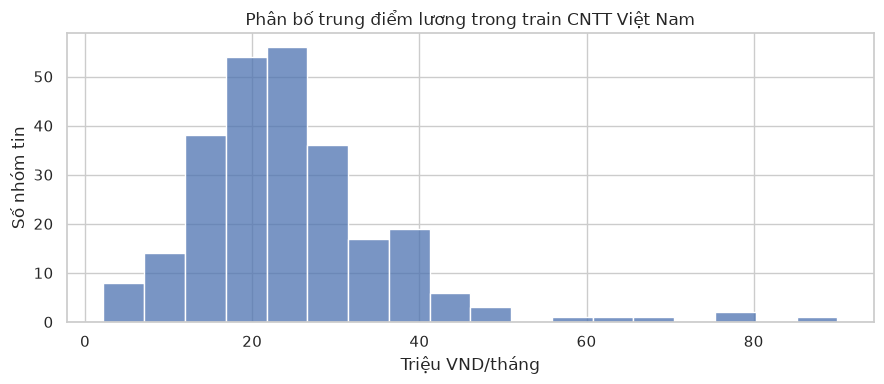

In [4]:
jobs = (train_eda.sort_values("record_id")
        .drop_duplicates("leakage_group_id").copy())
jobs["salary_million"] = jobs["salary_monthly_vnd"] / 1_000_000
display(jobs["salary_million"].describe().rename("triệu VND/tháng").to_frame())
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=jobs, x="salary_million", bins=18, ax=ax)
ax.set(title="Phân bố trung điểm lương trong train CNTT Việt Nam",
       xlabel="Triệu VND/tháng", ylabel="Số nhóm tin")
save_chart(fig, "salary_distribution_train")


## 5. Top kỹ năng xuất hiện

Đếm số nhóm tin có từng kỹ năng. Một tin có nhiều kỹ năng được tính ở nhiều cột;
các cột không cộng thành tổng số tin. Danh sách kỹ năng do nguồn cung cấp/trích xuất,
chưa được con người gán nhãn lại toàn bộ.

,job_groups
skill,
python,50
javascript,39
docker,34
git,34
java,34
html,27
postgresql,26
sql,24
css,24


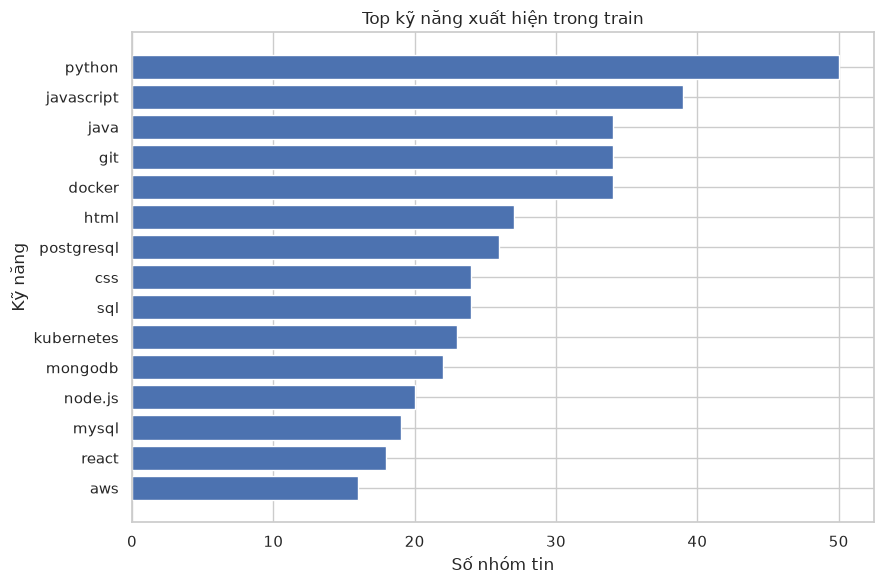

In [5]:
skill_rows = jobs[["record_id", "leakage_group_id", "salary_million", "skills_json"]].copy()
skill_rows["skill"] = skill_rows["skills_json"].map(json.loads)
skill_rows = skill_rows.explode("skill").dropna(subset=["skill"])
skill_rows["skill"] = skill_rows["skill"].str.strip().str.casefold()
skill_rows = skill_rows[skill_rows["skill"].ne("")]
skill_rows = skill_rows.drop_duplicates(["leakage_group_id", "skill"])
skill_counts = skill_rows.groupby("skill").size().rename("job_groups").sort_values(ascending=False)
skill_counts.to_csv(OUT / "skill_counts_train.csv")
display(skill_counts.head(20).to_frame())
top = skill_counts.head(15).sort_values()
if len(top):
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(top.index, top.values, color=sns.color_palette()[0])
    ax.set(title="Top kỹ năng xuất hiện trong train", xlabel="Số nhóm tin", ylabel="Kỹ năng")
    save_chart(fig, "top_skills_demand_train")


## 6. Kỹ năng gắn với median lương cao

Chỉ hiển thị kỹ năng có ít nhất 5 nhóm tin. Median của các nhóm khác nhau về vai trò,
seniority và địa điểm; **không diễn giải chênh lệch này thành mức tăng lương do học kỹ năng**.

,groups,median_million,mean_million
skill,,,
jenkins,6,36.250000,34.500000
terraform,5,35.000000,32.700000
restful apis,5,34.000000,32.000000
.net core,6,33.250000,31.833333
grafana,6,31.250000,32.833333
machine learning,5,30.000000,40.900000
svn,6,29.750000,29.000000
docker,34,29.166667,31.848039
prometheus,8,29.166667,31.916667


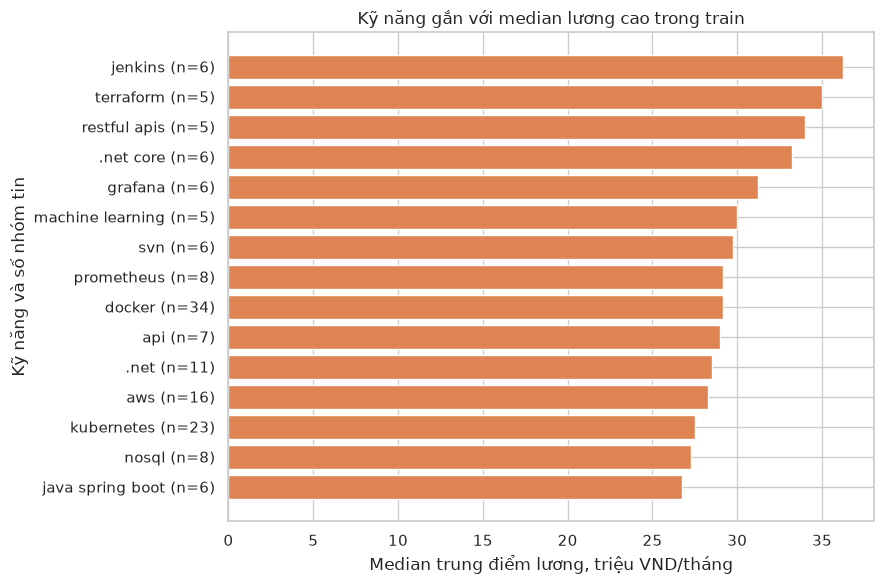

In [6]:
MIN_SKILL_GROUPS = 5
skill_salary = (skill_rows.groupby("skill").agg(
    groups=("leakage_group_id", "nunique"),
    median_million=("salary_million", "median"),
    mean_million=("salary_million", "mean"),
).query("groups >= @MIN_SKILL_GROUPS")
 .sort_values("median_million", ascending=False))
skill_salary.to_csv(OUT / "skill_salary_train.csv")
display(skill_salary.head(20))
top = skill_salary.head(15).sort_values("median_million")
if len(top):
    fig, ax = plt.subplots(figsize=(9, 6))
    labels = [f"{skill} (n={int(n)})" for skill, n in zip(top.index, top["groups"])]
    ax.barh(labels, top["median_million"], color=sns.color_palette()[1])
    ax.set(title="Kỹ năng gắn với median lương cao trong train",
           xlabel="Median trung điểm lương, triệu VND/tháng", ylabel="Kỹ năng và số nhóm tin")
    save_chart(fig, "top_skills_salary_train")
else:
    print("Không đủ số nhóm tin cho ngưỡng đã định; không hạ ngưỡng để tạo kết luận đẹp hơn.")


## 7. Kinh nghiệm và lương

Một số tin ghi khoảng/cận kinh nghiệm: `experience_years` có thể là cận dưới, không phải
số năm chính xác. Biểu đồ không xác nhận quan hệ nhân quả hoặc mức tăng lương mỗi năm.

Nhóm có kinh nghiệm dạng số: 256 / 257


,groups
experience_kind,
stated_years,237
explicit_zero,19


,experience_years,salary_million
"Spearman, mô tả train",,
experience_years,1.000000,0.514921
salary_million,0.514921,1.000000


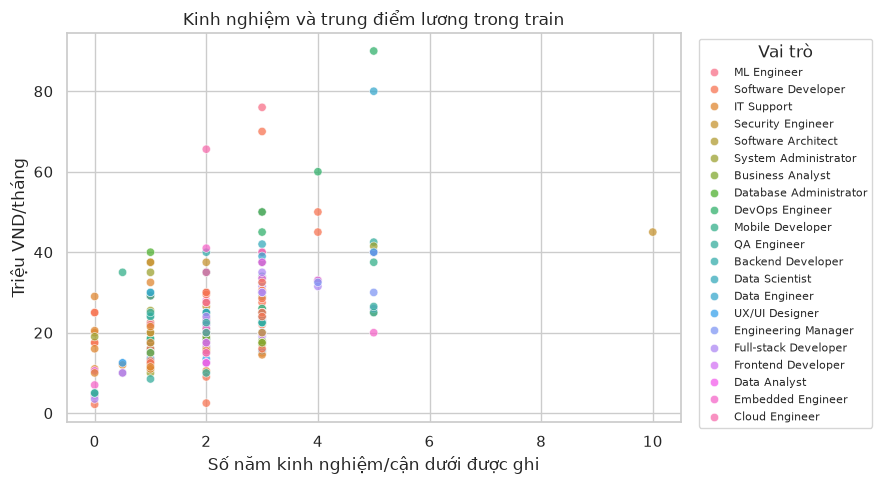

In [7]:
experienced = jobs.dropna(subset=["experience_years"]).copy()
print("Nhóm có kinh nghiệm dạng số:", len(experienced), "/", len(jobs))
display(experienced["experience_kind"].value_counts().to_frame("groups"))
if len(experienced) >= 3:
    display(experienced[["experience_years", "salary_million"]]
            .corr(method="spearman").rename_axis("Spearman, mô tả train"))
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.scatterplot(data=experienced, x="experience_years", y="salary_million",
                    hue="role", alpha=0.75, ax=ax)
    ax.set(title="Kinh nghiệm và trung điểm lương trong train",
           xlabel="Số năm kinh nghiệm/cận dưới được ghi", ylabel="Triệu VND/tháng")
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8, title="Vai trò")
    save_chart(fig, "experience_salary_train")


## 8. So sánh theo vai trò và địa điểm

,groups,median_million
role,,
Cloud Engineer,2,50.300000
Software Architect,2,40.000000
Database Administrator,2,37.500000
Data Engineer,6,32.000000
Data Scientist,3,30.000000
DevOps Engineer,13,29.166667
Engineering Manager,6,28.000000
ML Engineer,6,27.500000
Security Engineer,11,26.500000


,groups,median_million
location,,
Hà Nội,185,23.500000
TP.HCM,42,24.000000
hà đông,4,20.000000
bắc ninh,3,30.000000
Đà Nẵng,2,22.083333
cầu giấy,2,20.750000
hải phòng,2,15.500000
Bình Dương,1,25.000000
quảng ninh,1,10.000000


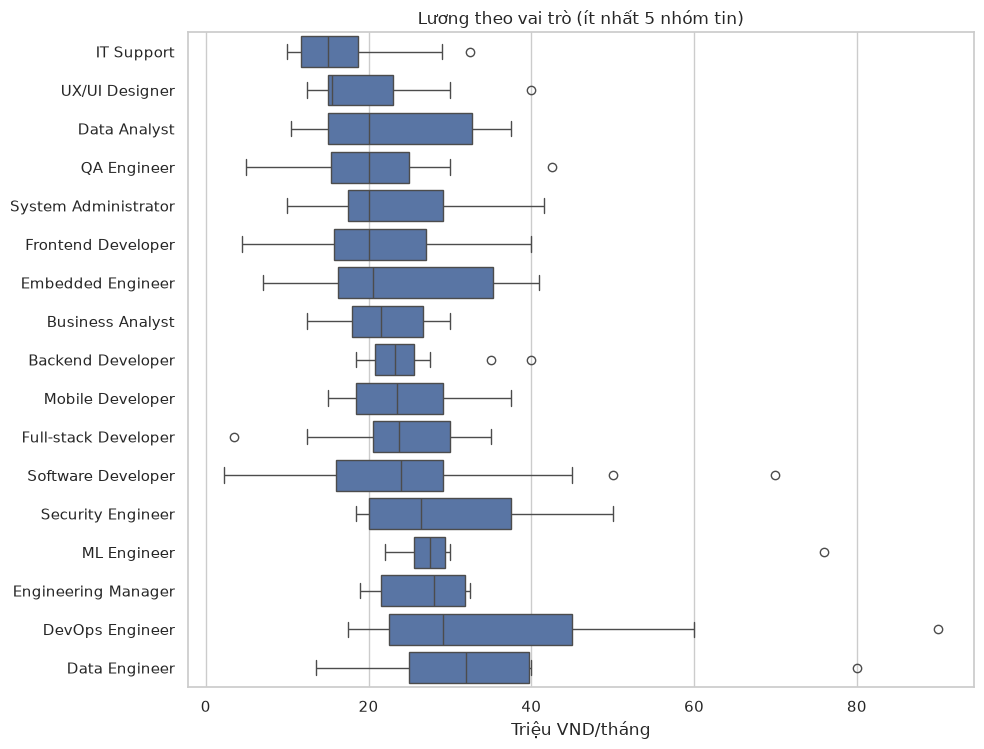

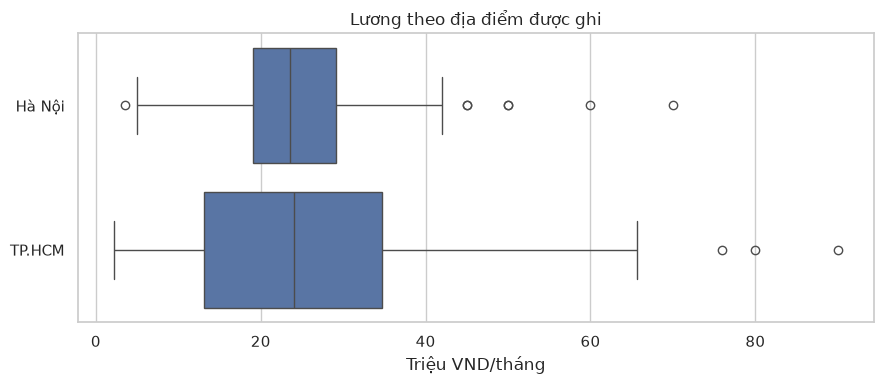

In [8]:
role_summary = jobs.groupby("role").agg(
    groups=("leakage_group_id", "nunique"), median_million=("salary_million", "median"))
location_summary = jobs.groupby("location", dropna=False).agg(
    groups=("leakage_group_id", "nunique"), median_million=("salary_million", "median"))
display(role_summary.sort_values("median_million", ascending=False))
display(location_summary.sort_values("groups", ascending=False))
role_summary.to_csv(OUT / "role_salary_train.csv")
location_summary.to_csv(OUT / "location_salary_train.csv")

roles = role_summary.query("groups >= 5").sort_values("median_million").index.tolist()
if roles:
    fig, ax = plt.subplots(figsize=(10, max(4, len(roles) * 0.45)))
    sns.boxplot(data=jobs[jobs["role"].isin(roles)], x="salary_million", y="role",
                order=roles, ax=ax)
    ax.set(title="Lương theo vai trò (ít nhất 5 nhóm tin)", xlabel="Triệu VND/tháng", ylabel="")
    save_chart(fig, "salary_by_role_train")

locations = location_summary.query("groups >= 5").sort_values("median_million").index.tolist()
if locations:
    fig, ax = plt.subplots(figsize=(9, max(4, len(locations) * 0.5)))
    sns.boxplot(data=jobs[jobs["location"].isin(locations)], x="salary_million", y="location",
                order=locations, ax=ax)
    ax.set(title="Lương theo địa điểm được ghi", xlabel="Triệu VND/tháng", ylabel="")
    save_chart(fig, "salary_by_location_train")


## 9. Độ phủ ngày đăng — không suy ra xu hướng toàn thị trường

VietJobs thiếu ngày đăng từng tin. Chỉ nối ngày từ bản clean cho ID đang thuộc train;
không dùng ngày crawl thay ngày đăng, không dùng khối lịch sử chưa rõ xuất xứ.

,total,dated
source_dataset,,
user_vietnam_it_jobs,54,54
vietjobs_2025,203,0


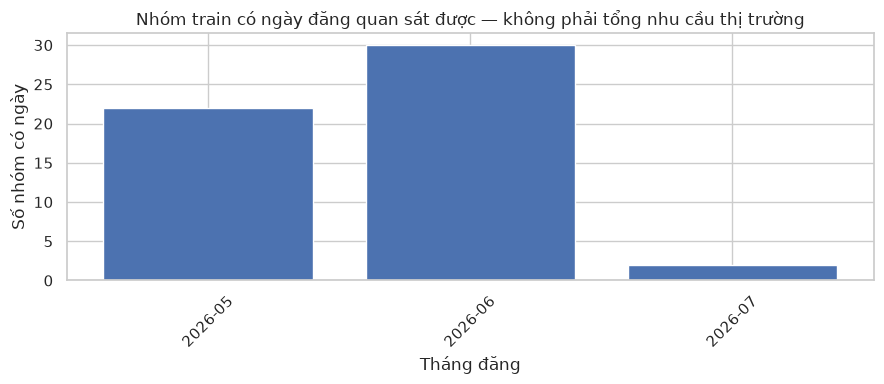

In [9]:
date_parts = []
for source in ["user_vietnam_it_jobs", "vietjobs_2025"]:
    source_entry = next(s for s in cleaning["sources"] if s["source"] == source)["files"]["clean"]
    path = ROOT / source_entry["path"]
    assert sha256_file(path) == source_entry["sha256"]
    date_parts.append(pd.read_csv(path, usecols=["record_id", "posted_at"]))
dates = pd.concat(date_parts, ignore_index=True)
dated = jobs[["record_id", "source_dataset"]].merge(dates, on="record_id", validate="one_to_one")
dated["posted_at"] = pd.to_datetime(dated["posted_at"], utc=True, errors="coerce", format="mixed")
display(dated.groupby("source_dataset")["posted_at"].agg(total="size", dated="count"))
observed = dated.dropna(subset=["posted_at"]).copy()
if len(observed):
    observed["month"] = observed["posted_at"].dt.strftime("%Y-%m")
    month_counts = observed.groupby("month").size().rename("observed_train_groups")
    month_counts.to_csv(OUT / "dated_train_groups_by_month.csv")
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar(month_counts.index, month_counts.values)
    ax.set(title="Nhóm train có ngày đăng quan sát được — không phải tổng nhu cầu thị trường",
           xlabel="Tháng đăng", ylabel="Số nhóm có ngày")
    ax.tick_params(axis="x", rotation=45)
    save_chart(fig, "observed_posted_dates_train")
else:
    print("Không có ngày đăng hợp lệ cho phần train này.")


## 10. Tổng hợp bằng chứng cho báo cáo

Khi viết kết luận, ghi rõ nguồn/năm, số nhóm tin, thiếu dữ liệu và đơn vị nhãn.
Không lấy median từng kỹ năng làm lời hứa thu nhập hoặc suy ra quan hệ nhân quả.
Notebook 02 sẽ dùng bộ developer riêng, giữ nguyên bộ chia đã đóng băng.

In [10]:
summary = {
    "cohort": COHORT, "split": "train", "split_version": SPLIT_VERSION,
    "input_sha256": entry["sha256"], "rows": len(train_eda), "job_groups": len(jobs),
    "unique_skill_tokens": int(len(skill_counts)),
    "skill_minimum_groups": MIN_SKILL_GROUPS,
    "target": "advertised_salary_midpoint_vnd_month_unknown_basis",
    "validation_or_test_labels_used": False,
    "limits": ["mẫu tin có lương công khai", "nhãn nguồn chưa phải gold",
               "thiếu ngày đăng", "cận dưới kinh nghiệm", "không suy luận nhân quả"],
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False) + "\n")
display(Markdown(f"**Đã lưu EDA:** `{OUT}`. Tiếp theo mở `02_salary_models.ipynb`."))


**Đã lưu EDA:** `/Users/scara2906/Downloads/ML/outputs/eda/20261017T092843Z_e3747c`. Tiếp theo mở `02_salary_models.ipynb`.